In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

# Настройки для красивого вывода графиков прямо в ноутбуке
%matplotlib inline
sns.set_theme(style="whitegrid")
warnings.filterwarnings('ignore')

# Загрузка данных (используем полный путь к папке Загрузки)
file_path = r'C:\Users\Пользователь\Downloads\dirty_employees.csv'
df = pd.read_csv(file_path)

# Вывод первых 5 строк
display(df.head())

,employee_id,age,salary,experience,rating,department,gender,education,hire_date
0,1,56.0,59927.0,17.0,1.1,Marketing,Female,Bachelor,2014-06-27
1,2,NaN,54250.0,27.0,2.2,IT,Female,Bachelor,2015-11-19
2,3,NaN,53062.0,21.0,4.1,HR,NaN,Master,2013-10-14
3,4,60.0,43312.0,20.0,2.1,Marketing,Male,PhD,2013-11-04
4,5,25.0,73008.0,5.0,1.9,Marketing,Male,Bachelor,2012-03-30


In [3]:
# 1. Общая информация о датасете (типы данных, количество непустых значений)
print("--- ИНФОРМАЦИЯ О ДАТАСЕТЕ ---")
df.info()

print("\n--- ОПИСАТЕЛЬНАЯ СТАТИСТИКА (Числовые признаки) ---")
# 2. Статистика по числовым признакам
display(df.describe())

print("\n--- ОПИСАТЕЛЬНАЯ СТАТИСТИКА (Категориальные признаки) ---")
# 3. Статистика по категориальным признакам (чтобы увидеть разнобой в написании)
display(df.describe(include=['object']))

--- ИНФОРМАЦИЯ О ДАТАСЕТЕ ---
<class 'pandas.DataFrame'>
RangeIndex: 305 entries, 0 to 304
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   employee_id  305 non-null    int64  
 1   age          280 non-null    str    
 2   salary       275 non-null    str    
 3   experience   272 non-null    float64
 4   rating       277 non-null    str    
 5   department   280 non-null    str    
 6   gender       281 non-null    str    
 7   education    278 non-null    str    
 8   hire_date    305 non-null    str    
dtypes: float64(1), int64(1), str(7)
memory usage: 21.6 KB

--- ОПИСАТЕЛЬНАЯ СТАТИСТИКА (Числовые признаки) ---


,employee_id,experience
count,305.000000,272.000000
mean,150.400000,19.970588
std,86.472448,11.938305
min,1.000000,0.000000
25%,76.000000,9.000000
50%,150.000000,21.000000
75%,225.000000,30.000000
max,300.000000,39.000000



--- ОПИСАТЕЛЬНАЯ СТАТИСТИКА (Категориальные признаки) ---


,age,salary,rating,department,gender,education,hire_date
count,280,275,277,280,281,278,305
unique,49,269,43,8,5,5,284
top,41.0,67015.0,3.1,Finance,Male,Master,2015-11-19
freq,12,2,13,61,142,106,2


## 1. Изучение данных и приведение типов
По результатам `df.info()` видно, что числовые признаки `age`, `salary`, `rating` имеют тип `str` из-за некорректных значений (букв, пробелов, знаков %). Признак `hire_date` также является строкой. Приведем их к правильным типам.

In [5]:
# Функция для очистки числовых признаков от текста
def clean_numeric(x):
    if pd.isna(x):
        return x
    if isinstance(x, str):
        # Убираем пробелы и знаки процента, заменяем запятые на точки
        x = x.replace(' ', '').replace('%', '').replace(',', '.')
        # Убираем любой текст (например, "years")
        x = ''.join(c for c in x if c.isdigit() or c == '.')
    try:
        return float(x)
    except:
        return np.nan

# Применяем функцию к нужным столбцам
df['age'] = df['age'].apply(clean_numeric)
df['salary'] = df['salary'].apply(clean_numeric)
df['rating'] = df['rating'].apply(clean_numeric)

# Переводим дату в формат datetime
df['hire_date'] = pd.to_datetime(df['hire_date'], errors='coerce')

# Проверяем, что типы изменились
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 305 entries, 0 to 304
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   employee_id  305 non-null    int64         
 1   age          280 non-null    float64       
 2   salary       275 non-null    float64       
 3   experience   272 non-null    float64       
 4   rating       277 non-null    float64       
 5   department   280 non-null    str           
 6   gender       281 non-null    str           
 7   education    278 non-null    str           
 8   hire_date    305 non-null    datetime64[us]
dtypes: datetime64[us](1), float64(4), int64(1), str(3)
memory usage: 21.6 KB


## 2. Обнаружение и обработка дубликатов
Проверим наличие полных дубликатов (одинаковые строки) и частичных (например, одинаковые ID сотрудников).

In [6]:
# 1. Полные дубликаты
full_dups = df.duplicated().sum()
print(f"Количество полных дубликатов: {full_dups}")

# 2. Частичные дубликаты по ID (employee_id)
partial_dups = df.duplicated(subset=['employee_id']).sum()
print(f"Количество дубликатов по employee_id: {partial_dups}")

# Вывод примеры дубликатов по ID
display(df[df.duplicated(subset=['employee_id'], keep=False)].sort_values('employee_id'))

Количество полных дубликатов: 5
Количество дубликатов по employee_id: 5


,employee_id,age,salary,experience,rating,department,gender,education,hire_date
47,48,43.0,67015.0,38.0,3.4,IT,Female,Master,2023-04-02
300,48,43.0,67015.0,38.0,3.4,IT,Female,Master,2023-04-02
301,94,18.0,52523.0,27.0,2.6,HR,Male,Bachelor,2014-08-02
93,94,18.0,52523.0,27.0,2.6,HR,Male,Bachelor,2014-08-02
302,143,32.0,69492.0,37.0,4.4,Sales,Female,NaN,2022-07-20
142,143,32.0,69492.0,37.0,4.4,Sales,Female,NaN,2022-07-20
208,209,40.0,57850.0,NaN,3.1,IT,Male,PhD,2013-11-29
303,209,40.0,57850.0,NaN,3.1,IT,Male,PhD,2013-11-29
227,228,23.0,75557.0,28.0,1.4,Finance,NaN,Master,2013-01-29
304,228,23.0,75557.0,28.0,1.4,Finance,NaN,Master,2013-01-29


**Анализ и обработка:** Обнаружены полные дубликаты (5 записей) и дубликаты по `employee_id`. Так как ID сотрудника должен быть уникальным, оставляем только первое появление записи.

In [7]:
# Удаляем дубликаты (оставляем первое вхождение)
df = df.drop_duplicates(subset=['employee_id'], keep='first')
# На всякий случай удаляем полные дубликаты
df = df.drop_duplicates()

print(f"Размер датасета после удаления дубликатов: {df.shape}")

Размер датасета после удаления дубликатов: (300, 9)


## 3. Заполнение пропусков
В данных есть пропуски (NaN). Заполним числовые признаки медианой (устойчива к выбросам), а категориальные — модой (самым частым значением).

In [8]:
# Заполнение числовых признаков медианой
df['age'] = df['age'].fillna(df['age'].median())
df['salary'] = df['salary'].fillna(df['salary'].median())
df['rating'] = df['rating'].fillna(df['rating'].median())
df['experience'] = df['experience'].fillna(df['experience'].median())

# Заполнение категориальных признаков модой
cat_cols = ['department', 'gender', 'education']
for col in cat_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

# Проверяем, что пропусков не осталось
print("Пропуски после заполнения:")
display(df.isnull().sum())

Пропуски после заполнения:


employee_id    0
age            0
salary         0
experience     0
rating         0
department     0
gender         0
education      0
hire_date      0
dtype: int64

## 4. Выявление выбросов (IQR и Z-score)
Выбросы можно найти статистически (метод межквартильного размаха IQR и Z-оценки) и логически (проверка диапазонов).

In [10]:
# 1. Логическая проверка диапазонов (возраст 0-100, зарплата > 0)
print("Сотрудники с некорректным возрастом (<0 или >100):")
display(df[(df['age'] < 0) | (df['age'] > 100)][['employee_id', 'age']])

print("\nСотрудники с некорректной зарплатой (> 1 млн):")
display(df[df['salary'] > 1000000][['employee_id', 'salary']])

# 2. Метод IQR для зарплаты
Q1 = df['salary'].quantile(0.25)
Q3 = df['salary'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers_iqr = df[(df['salary'] < lower_bound) | (df['salary'] > upper_bound)]
print(f"\nВыбросы по зарплате (метод IQR): {len(outliers_iqr)} шт.")

# 3. Метод Z-score для зарплаты (считаем вручную через numpy)
mean_salary = df['salary'].mean()
std_salary = df['salary'].std()
z_scores = np.abs((df['salary'] - mean_salary) / std_salary)
outliers_z = df[z_scores > 3]
print(f"Выбросы по зарплате (метод Z-score, z > 3): {len(outliers_z)} шт.")

Сотрудники с некорректным возрастом (<0 или >100):


,employee_id,age
291,292,150.0



Сотрудники с некорректной зарплатой (> 1 млн):


,employee_id,salary
243,244,2000000.0



Выбросы по зарплате (метод IQR): 2 шт.
Выбросы по зарплате (метод Z-score, z > 3): 1 шт.


**Вывод:** Метод IQR нашел больше выбросов, так как он чувствителен к форме распределения (зарплаты часто имеют скошенное вправо распределение). Z-score нашел только экстремальные значения (например, зарплату 2 000 000). Ошибочные значения (возраст 150) будем удалять/заменять логически.

In [11]:
# Обработка выбросов: 
# 1. Возраст больше 100 - это явная ошибка, заменяем на медиану
median_age = df['age'].median()
df.loc[df['age'] > 100, 'age'] = median_age

# 2. Зарплату 2 000 000 считаем аномалией (выбросом), заменяем на медиану
median_salary = df['salary'].median()
df.loc[df['salary'] > 1000000, 'salary'] = median_salary

print("Экстремальные значения заменены на медианы.")

Экстремальные значения заменены на медианы.


## 5. Мини-кейс Data Cleaning
Сымитируем получение "грязного" файла от заказчика: внесем искусственные ошибки, а затем восстановим данные с помощью написанных функций.

In [14]:
import random
import numpy as np

# Берем чистый датасет (копию)
df_clean = df.copy()
df_dirty = df.copy()

# ВАЖНО: переводим колонку age в тип "object" (строка), чтобы можно было записать туда текст "двадцать"
df_dirty['age'] = df_dirty['age'].astype(object)

# 1. Вносим 5% пропусков в зарплату и рейтинг
np.random.seed(42)
mask = np.random.rand(len(df_dirty)) < 0.05
df_dirty.loc[mask, 'salary'] = np.nan
mask2 = np.random.rand(len(df_dirty)) < 0.05
df_dirty.loc[mask2, 'rating'] = np.nan

# 2. Вносим выбросы (зарплата 5000000). Ищем по employee_id!
df_dirty.loc[df_dirty['employee_id'] == 5, 'salary'] = 5000000

# 3. Некорректные значения (возраст "двадцать")
df_dirty.loc[df_dirty['employee_id'] == 10, 'age'] = "двадцать"

# 4. Ошибки в категориях
df_dirty.loc[df_dirty['employee_id'] == 15, 'department'] = "ITTT"
df_dirty.loc[df_dirty['employee_id'] == 20, 'gender'] = "Mle"

# 5. Дубликаты (берем первые три строки и добавляем в конец)
df_dirty = pd.concat([df_dirty, df_dirty.head(3)], ignore_index=True)

print("Грязный датасет создан. Размер:", df_dirty.shape)

Грязный датасет создан. Размер: (303, 9)


**Восстановление данных (Аудит):** Применим написанные ранее функции к "грязному" датасету.

In [15]:
# Аудит: снова чистим типы, дубликаты и пропуски
df_audit = df_dirty.copy()

# Исправляем типы
df_audit['age'] = df_audit['age'].apply(clean_numeric)
df_audit['salary'] = df_audit['salary'].apply(clean_numeric)
df_audit['rating'] = df_audit['rating'].apply(clean_numeric)

# Удаляем дубликаты
df_audit = df_audit.drop_duplicates(subset=['employee_id'], keep='first')

# Заполняем пропуски
df_audit['salary'] = df_audit['salary'].fillna(df_audit['salary'].median())
df_audit['rating'] = df_audit['rating'].fillna(df_audit['rating'].median())
df_audit['age'] = df_audit['age'].fillna(df_audit['age'].median())

# Чистим категории (заменяем ошибки)
df_audit['department'] = df_audit['department'].replace({'ITTT': 'IT', 'Sale': 'Sales', ' it ': 'IT'})
df_audit['gender'] = df_audit['gender'].replace({'Mle': 'Male', 'male': 'Male', 'FEMALE': 'Female'})

# Убираем выбросы
df_audit.loc[df_audit['salary'] > 1000000, 'salary'] = df_audit['salary'].median()
df_audit.loc[df_audit['age'] > 100, 'age'] = df_audit['age'].median()

print("Аудит завершен. Размер чистого датасета:", df_audit.shape)
print("\nСравнение статистик до и после:")
display(df_clean.describe())
display(df_audit.describe())

Аудит завершен. Размер чистого датасета: (300, 9)

Сравнение статистик до и после:


,employee_id,age,salary,experience,rating,hire_date
count,300.000000,300.000000,300.000000,300.000000,300.000000,300
mean,150.500000,40.816667,59721.161667,19.913333,3.096667,2016-08-14 20:00:00
min,1.000000,18.000000,23112.000000,0.000000,1.000000,2010-01-17 00:00:00
25%,75.750000,30.000000,50097.500000,10.000000,2.275000,2013-01-28 00:00:00
50%,150.500000,41.000000,59700.500000,21.000000,3.100000,2016-08-28 12:00:00
75%,225.250000,52.000000,68878.250000,29.000000,4.000000,2019-12-23 12:00:00
max,300.000000,64.000000,107805.000000,39.000000,9.900000,2025-01-15 00:00:00
std,86.746758,13.096876,14990.006956,11.262711,1.172849,NaN


,employee_id,age,salary,experience,rating,hire_date
count,300.000000,300.000000,300.000000,300.000000,300.000000,300
mean,150.500000,40.860000,59815.478333,19.913333,3.102000,2016-08-14 20:00:00
min,1.000000,18.000000,23112.000000,0.000000,1.000000,2010-01-17 00:00:00
25%,75.750000,30.750000,50769.000000,10.000000,2.300000,2013-01-28 00:00:00
50%,150.500000,41.000000,59700.500000,21.000000,3.100000,2016-08-28 12:00:00
75%,225.250000,52.000000,67547.250000,29.000000,3.900000,2019-12-23 12:00:00
max,300.000000,64.000000,107805.000000,39.000000,9.900000,2025-01-15 00:00:00
std,86.746758,13.075817,14613.816680,11.262711,1.141317,NaN


## 6. Визуализация: Тепловая карта пропусков и Ящиковые диаграммы

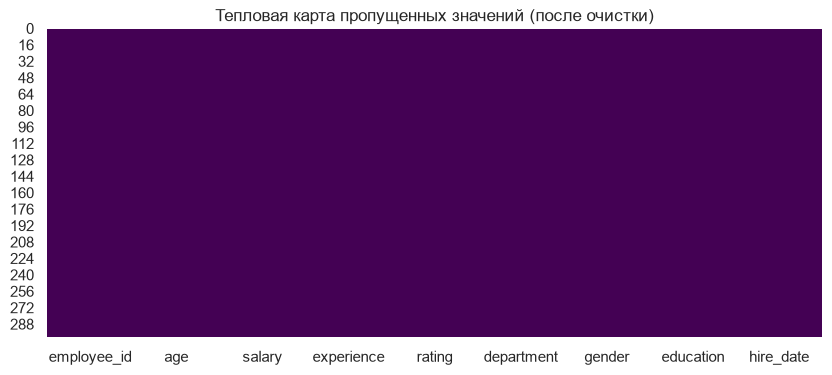

In [16]:
plt.figure(figsize=(10, 4))
sns.heatmap(df.isnull(), cbar=False, cmap='viridis')
plt.title('Тепловая карта пропущенных значений (после очистки)')
plt.show()

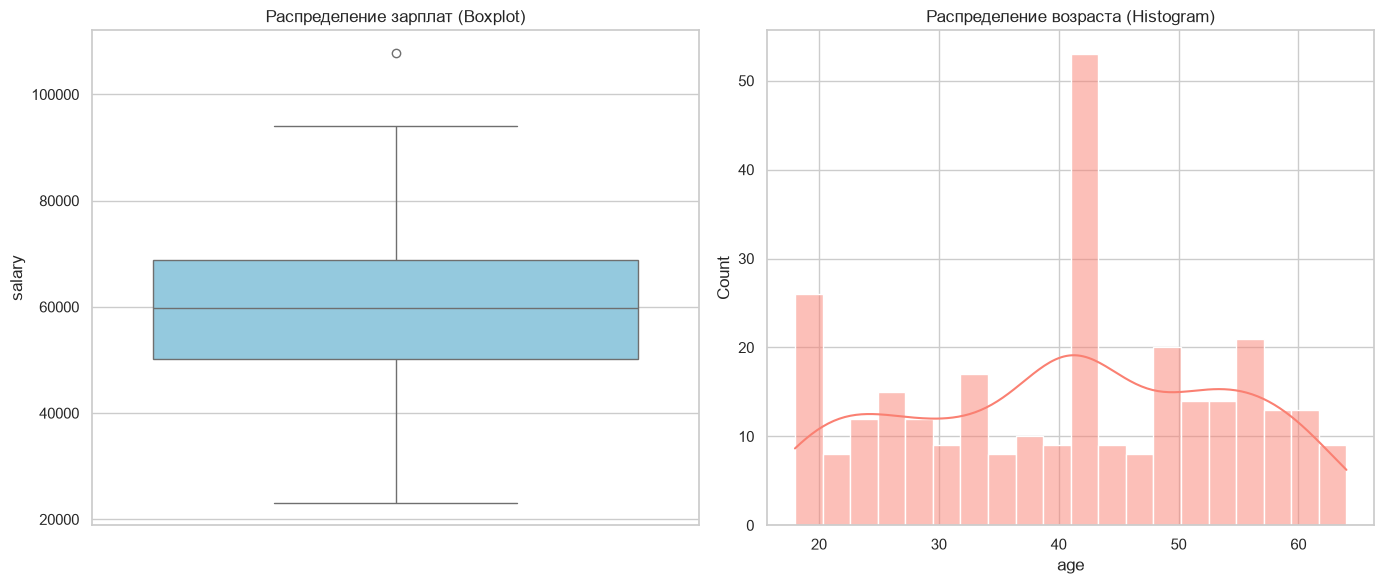

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Ящиковая диаграмма для зарплаты
sns.boxplot(y=df['salary'], ax=axes[0], color='skyblue')
axes[0].set_title('Распределение зарплат (Boxplot)')

# Гистограмма для возраста
sns.histplot(df['age'], bins=20, kde=True, ax=axes[1], color='salmon')
axes[1].set_title('Распределение возраста (Histogram)')

plt.tight_layout()
plt.show()